[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wellingtonmnf/pos-graduacao-ia-ciencia-dados/blob/main/disciplinas/processamento-linguagem-natural/notebooks/unidade-03/classificacao-com-word-embedding.ipynb)


In [1]:
# Revisão documental — 20/10/2026.
# Saídas históricas preservadas. C19: a contagem de tokens ainda traz o rótulo histórico “teste”, hoje
# identificado como validação. C29/C34: os rótulos “Teste” salvos precedem a identificação atual do
# conjunto como validação. Execução integral desta revisão no Colab pendente.

# Preparação da dependência usada pelo adaptador Pandas.
%pip install "kagglehub[pandas-datasets]"
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Defina o nome do arquivo correto do dataset
file_path = "IMDB Dataset.csv"

# Carrega a versão 1, comparada em 2026-10-19, preservando a ordem das resenhas.
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/versions/1",
  file_path
)

if not {"review", "sentiment"}.issubset(df.columns):
    raise ValueError("Colunas inesperadas no IMDb")
if df["review"].isna().any() or not df["review"].map(lambda x: isinstance(x, str) and bool(x.strip())).all():
    raise ValueError("Resenhas ausentes ou inválidas")
if df["sentiment"].isna().any() or not df["sentiment"].isin(["positive", "negative"]).all():
    raise ValueError("Rótulos inesperados no IMDb")

print("Primeiros 5 registros:")
display(df.head())

# Alcance da avaliação
#
# Este exemplo usa uma divisão didática em treino e validação. Os nomes `X_test`, `y_test`, `tk_pad_X_test` e `ohe_y_test` foram mantidos no código, mas identificam o conjunto usado em `validation_data` para monitoramento a cada época. Cada chamada posterior a `evaluate` reutiliza esses mesmos dados; sua acurácia descreve o conjunto usado para validação. Não há uma reserva de teste independente para avaliar escolhas baseadas nesse monitoramento ou na comparação das variantes.
#
# As saídas salvas são históricas: rótulos antigos como “Acurácia do Teste” não demonstram avaliação independente e não representam uma nova execução das fontes corrigidas.

Using Colab cache for faster access to the 'imdb-dataset-of-50k-movie-reviews' dataset.
Primeiros 5 registros:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [2]:
df.isnull().sum()

,0
review,0
sentiment,0


In [3]:
df['sentiment'].value_counts()

,count
sentiment,
positive,25000
negative,25000


<Axes: title={'center': 'Quantidade por Tipo'}, xlabel='sentiment'>

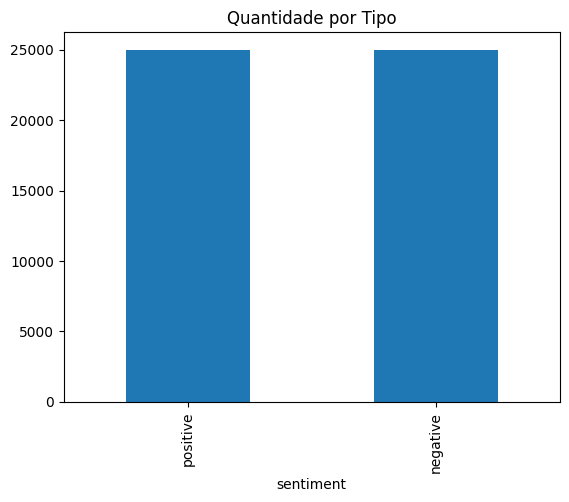

In [4]:
df["sentiment"].value_counts().plot.bar(title='Quantidade por Tipo',rot=90)

In [5]:
!pip install nltk
import nltk
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [6]:
exemplo = df['review'].values[0]
print(exemplo)
print(len(exemplo.split()))

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due to the fac

In [7]:
from nltk.tokenize import word_tokenize
import string

stopwords = nltk.corpus.stopwords.words('english')
punctuations = list(string.punctuation)

def prepara(texto):
    palavras = [i for i in word_tokenize(texto, language='english') if i not in punctuations]
    palavras = [i for i in palavras if i not in stopwords]
    return palavras

exemplo_preparado = prepara(exemplo)
print(exemplo_preparado)
print(len(exemplo_preparado))

['One', 'reviewers', 'mentioned', 'watching', '1', 'Oz', 'episode', "'ll", 'hooked', 'They', 'right', 'exactly', 'happened', 'me.', 'br', 'br', 'The', 'first', 'thing', 'struck', 'Oz', 'brutality', 'unflinching', 'scenes', 'violence', 'set', 'right', 'word', 'GO', 'Trust', 'show', 'faint', 'hearted', 'timid', 'This', 'show', 'pulls', 'punches', 'regards', 'drugs', 'sex', 'violence', 'Its', 'hardcore', 'classic', 'use', 'word.', 'br', 'br', 'It', 'called', 'OZ', 'nickname', 'given', 'Oswald', 'Maximum', 'Security', 'State', 'Penitentary', 'It', 'focuses', 'mainly', 'Emerald', 'City', 'experimental', 'section', 'prison', 'cells', 'glass', 'fronts', 'face', 'inwards', 'privacy', 'high', 'agenda', 'Em', 'City', 'home', 'many', '..', 'Aryans', 'Muslims', 'gangstas', 'Latinos', 'Christians', 'Italians', 'Irish', '....', 'scuffles', 'death', 'stares', 'dodgy', 'dealings', 'shady', 'agreements', 'never', 'far', 'away.', 'br', 'br', 'I', 'would', 'say', 'main', 'appeal', 'show', 'due', 'fact', 

In [8]:
from nltk.tokenize import word_tokenize
import string
stopwords = nltk.corpus.stopwords.words('english')
punctuations = list(string.punctuation)
TAMANHO_MIMINO = 1
IGNORAR = ['...', 'br','.so','\'ll']

from nltk.stem import SnowballStemmer
stemmer = SnowballStemmer('english')
def prepara(texto):
    palavras = [i for i in word_tokenize(texto, language='english') if i not in punctuations]
    palavras = [i for i in palavras if i not in stopwords]
    palavras = [i for i in palavras if len(i) > TAMANHO_MIMINO]
    palavras = [i for i in palavras if i not in IGNORAR]
    palavras = [stemmer.stem(i) for i in palavras]
    return palavras
exemplo_preparado = prepara(exemplo)
print(exemplo_preparado)
print(len(exemplo_preparado))

['one', 'review', 'mention', 'watch', 'oz', 'episod', 'hook', 'they', 'right', 'exact', 'happen', 'me.', 'the', 'first', 'thing', 'struck', 'oz', 'brutal', 'unflinch', 'scene', 'violenc', 'set', 'right', 'word', 'go', 'trust', 'show', 'faint', 'heart', 'timid', 'this', 'show', 'pull', 'punch', 'regard', 'drug', 'sex', 'violenc', 'it', 'hardcor', 'classic', 'use', 'word.', 'it', 'call', 'oz', 'nicknam', 'given', 'oswald', 'maximum', 'secur', 'state', 'penitentari', 'it', 'focus', 'main', 'emerald', 'citi', 'experiment', 'section', 'prison', 'cell', 'glass', 'front', 'face', 'inward', 'privaci', 'high', 'agenda', 'em', 'citi', 'home', 'mani', '..', 'aryan', 'muslim', 'gangsta', 'latino', 'christian', 'italian', 'irish', '....', 'scuffl', 'death', 'stare', 'dodgi', 'deal', 'shadi', 'agreement', 'never', 'far', 'away.', 'would', 'say', 'main', 'appeal', 'show', 'due', 'fact', 'goe', 'show', 'would', "n't", 'dare', 'forget', 'pretti', 'pictur', 'paint', 'mainstream', 'audienc', 'forget', 'c

In [9]:
%%time
df['review2'] = df['review'].apply(prepara)
df['review2'] = df['review2'].apply(' '.join)

CPU times: user 2min 57s, sys: 568 ms, total: 2min 57s
Wall time: 3min


In [10]:
df.head()

,review,sentiment,review2
0,One of the other reviewers has mentioned that ...,positive,one review mention watch oz episod hook they r...
1,A wonderful little production. <br /><br />The...,positive,wonder littl product the film techniqu unassum...
2,I thought this was a wonderful way to spend ti...,positive,thought wonder way spend time hot summer weeke...
3,Basically there's a family where a little boy ...,negative,basic 's famili littl boy jake think 's zombi ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,petter mattei 's `` love time money '' visual ...


In [11]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df['review2'], df['sentiment'], test_size=0.2, random_state=0)
print('X_train shape:',X_train.shape)
print('y_train shape:',y_train.shape)
print('X_test shape:',X_test.shape)
print('y_test shape:',y_test.shape)

X_train shape: (40000,)
y_train shape: (40000,)
X_test shape: (10000,)
y_test shape: (10000,)


In [12]:
%%time
from tensorflow.keras.preprocessing.text import Tokenizer

tokenizer = Tokenizer(num_words=10000)

CPU times: user 3.63 s, sys: 444 ms, total: 4.07 s
Wall time: 4.66 s


In [13]:
# fit_on_texts varre todo o X_train e constrói o word_index completo,
# independente do limite de num_words — a restrição só vale na conversão.
tokenizer.fit_on_texts(X_train)

In [14]:
tk_X_train = tokenizer.texts_to_sequences(X_train)
tk_X_test  = tokenizer.texts_to_sequences(X_test)

In [15]:
# O +1 reserva o índice 0 para o padding, que será usado em etapas futuras.
vocab_size = len(tokenizer.word_index) + 1

In [16]:
# X_train é uma Series do pandas com índices embaralhados pelo train_test_split.
# X_train[0] busca pelo RÓTULO 0, que pode não existir ou apontar para
# uma review diferente da posição 0 da sequência numérica.
# A solução é usar .iloc[0], que acessa sempre pela POSIÇÃO real.
print("Texto original:     ", X_train.iloc[0])
print("Sequência numérica: ", tk_X_train[0])

Texto original:      that 's redeem qualiti movi otherwis insult viewer 's intellig lose track time plot reason produced. plus guy glass ever got gig hollywood beyond
Sequência numérica:  [136, 1, 1230, 419, 2, 888, 1267, 304, 1, 699, 790, 951, 10, 48, 161, 899, 85, 1863, 64, 118, 4544, 333, 644]


In [17]:
# Verificação de sanidade: confirma que texto e sequência correspondem
# Útil para rodar sempre que você modificar o pipeline de dados
print("\n--- Verificação de sanidade ---")
print("Índices reais do X_train:", X_train.index[:5].tolist())
print("Primeiras palavras: ", X_train.iloc[0][:60])
print("Primeiros 10 tokens:", tk_X_train[0][:10])


--- Verificação de sanidade ---
Índices reais do X_train: [20330, 17532, 45819, 34807, 31888]
Primeiras palavras:  that 's redeem qualiti movi otherwis insult viewer 's intell
Primeiros 10 tokens: [136, 1, 1230, 419, 2, 888, 1267, 304, 1, 699]


In [25]:
total_tokens_train = sum(len(seq) for seq in tk_X_train)
total_tokens_test = sum(len(seq) for seq in tk_X_test)

print(f'Total de tokens nos dados de treino: {total_tokens_train}')
print(f'Total de tokens nos dados de validação: {total_tokens_test}')

Total de tokens nos dados de treino: 5070712
Total de tokens nos dados de teste: 1275527


In [22]:
print('vocab_size:',vocab_size)

vocab_size: 73652


In [24]:
for word in ['movi','film','the','one']:
    print('{}: {}'.format(word, tokenizer.word_index[word]))

movi: 2
film: 3
the: 4
one: 7


In [26]:
print('Max size:',max([len(i) for i in tk_X_train]))

Max size: 1374


In [29]:
from keras.utils import pad_sequences
maxlen = max([len(i) for i in tk_X_train])
tk_pad_X_train = pad_sequences(tk_X_train, padding='post', maxlen=maxlen)
tk_pad_X_test = pad_sequences(tk_X_test, padding='post', maxlen=maxlen)
print(tk_pad_X_train[0, :])

[ 136    1 1230 ...    0    0    0]


In [30]:
from sklearn.preprocessing import LabelBinarizer
lb = LabelBinarizer()
ohe_y_train = lb.fit_transform(y_train)
ohe_y_test = lb.transform(y_test)
print('ohe_y_train shape:',ohe_y_train.shape)
print('ohe_y_test shape:',ohe_y_test.shape)

ohe_y_train shape: (40000, 1)
ohe_y_test shape: (10000, 1)


In [31]:
from keras.models import Sequential
from keras.layers import Embedding, Flatten, Dense, GlobalMaxPool1D, Dropout, Conv1D, GlobalMaxPooling1D
from keras.optimizers import Adam

In [32]:
NB_EPOCH = 20
BATCH_SIZE = 128
VERBOSE = 1
OPTIMIZER = Adam()

In [35]:
from keras import Input

model = Sequential()
model.add(Input(shape=(maxlen,), dtype="int32"))
model.add(Embedding(input_dim=vocab_size, output_dim=50))
model.add(Flatten())
model.add(Dense(10, activation='relu'))
model.add(Dense(1, activation='sigmoid'))
model.compile(optimizer=OPTIMIZER, loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [36]:
%%time
# O conjunto de validação monitorado aqui é reutilizado na avaliação abaixo.
history = model.fit(tk_pad_X_train, ohe_y_train,
                    epochs=NB_EPOCH,
                    verbose=1,
                    validation_data=(tk_pad_X_test, ohe_y_test),
                    batch_size=BATCH_SIZE)

Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 60s 186ms/step - accuracy: 0.4979 - loss: 0.7003 - val_accuracy: 0.4965 - val_loss: 0.6932
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 59s 189ms/step - accuracy: 0.4990 - loss: 0.6931 - val_accuracy: 0.4965 - val_loss: 0.6932
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 83s 192ms/step - accuracy: 0.4977 - loss: 0.6931 - val_accuracy: 0.5035 - val_loss: 0.6931
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 80s 187ms/step - accuracy: 0.4993 - loss: 0.6931 - val_accuracy: 0.4965 - val_loss: 0.6932
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 59s 189ms/step - accuracy: 0.4995 - loss: 0.6931 - val_accuracy: 0.4965 - val_loss: 0.6932
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 65s 207ms/step - accuracy: 0.5002 - loss: 0.6931 - val_accuracy: 0.5035 - val_loss: 0.6931
Epoch 7/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 78s 193ms/step - accuracy: 0.4979 - loss: 0.6932 - val_accuracy: 0.4965 - val_loss: 0.6932
Epoch 8/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 81s 192ms/step - accuracy: 0.4983 - loss: 0

In [37]:
# Avaliação nos mesmos dados usados para validação durante o treino.
loss, accuracy = model.evaluate(tk_pad_X_test, ohe_y_test, verbose=False)
print("Acurácia no conjunto usado para validação:  {:.4f}".format(accuracy))

Acurácia do Teste:  0.4965


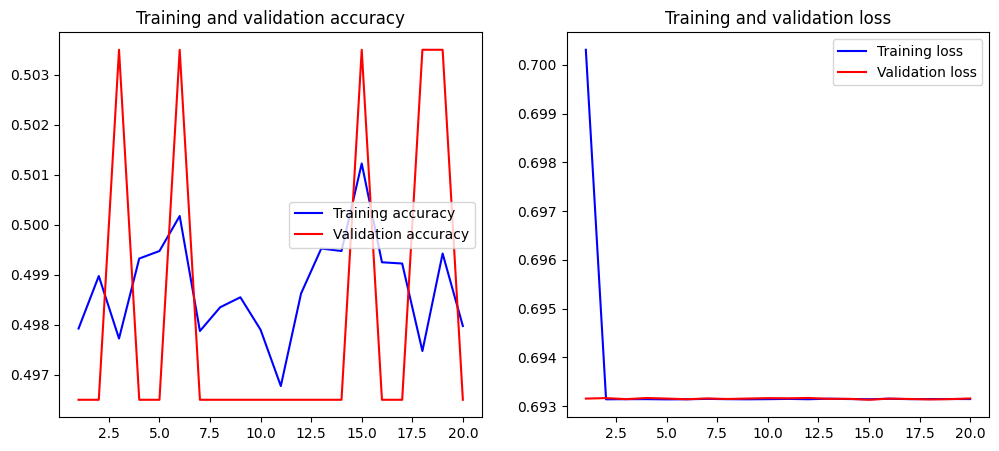

In [38]:
import matplotlib.pyplot as plt
def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    x = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(x, acc, 'b', label='Training accuracy')
    plt.plot(x, val_acc, 'r', label='Validation accuracy')
    plt.title('Training and validation accuracy')
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(x, loss, 'b', label='Training loss')
    plt.plot(x, val_loss, 'r', label='Validation loss')
    plt.title('Training and validation loss')
    plt.legend()
plot_history(history)

In [41]:
NB_EPOCH = 10
BATCH_SIZE = 128
VERBOSE = 1
OPTIMIZER = Adam()

In [42]:
from keras import Input

model = Sequential()
model.add(Input(shape=(maxlen,), dtype="int32"))
model.add(Embedding(input_dim=vocab_size, output_dim=50))
model.add(GlobalMaxPool1D())
model.add(Dense(16, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(1, activation='sigmoid'))
model.compile(optimizer=OPTIMIZER, loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_1          │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [43]:
%%time
# O conjunto de validação monitorado aqui é reutilizado na avaliação abaixo.
history = model.fit(tk_pad_X_train, ohe_y_train,
                    epochs=NB_EPOCH,
                    verbose=1,
                    validation_data=(tk_pad_X_test, ohe_y_test),
                    batch_size=BATCH_SIZE)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 57s 179ms/step - accuracy: 0.7264 - loss: 0.5603 - val_accuracy: 0.8399 - val_loss: 0.3955
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 58s 186ms/step - accuracy: 0.8546 - loss: 0.3654 - val_accuracy: 0.8665 - val_loss: 0.3178
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 81s 183ms/step - accuracy: 0.8893 - loss: 0.2939 - val_accuracy: 0.8746 - val_loss: 0.2961
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 183ms/step - accuracy: 0.9124 - loss: 0.2481 - val_accuracy: 0.8765 - val_loss: 0.2926
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 182ms/step - accuracy: 0.9323 - loss: 0.2050 - val_accuracy: 0.8776 - val_loss: 0.2990
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 56s 179ms/step - accuracy: 0.9464 - loss: 0.1682 - val_accuracy: 0.8763 - val_loss: 0.3128
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 56s 180ms/step - accuracy: 0.9587 - loss: 0.1409 - val_accuracy: 0.8742 - val_loss: 0.3342
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 57s 181ms/step - accuracy: 0.9674 - loss: 0

In [44]:
# Avaliação nos mesmos dados usados para validação durante o treino.
loss, accuracy = model.evaluate(tk_pad_X_test, ohe_y_test, verbose=False)
print("Acurácia no conjunto usado para validação:  {:.4f}".format(accuracy))

Acurácia do Teste:  0.8733


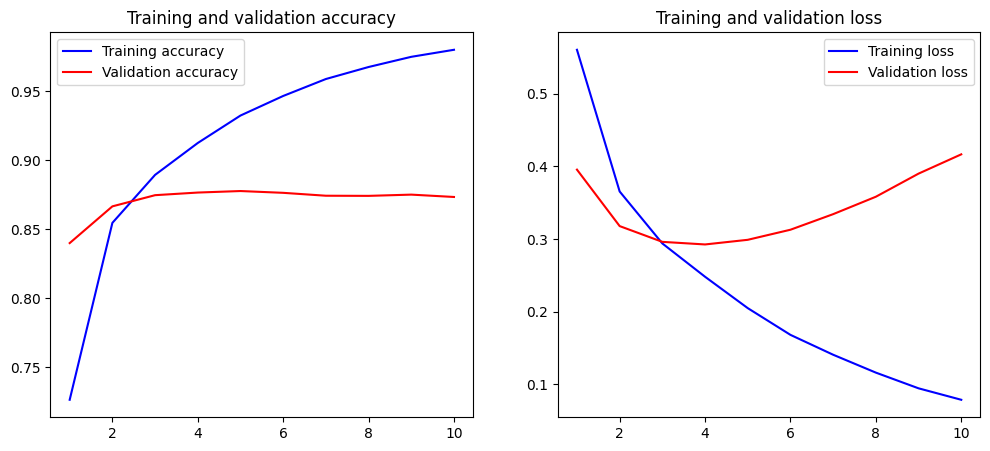

In [46]:
plot_history(history)